<a href="https://colab.research.google.com/github/nuralamfajar/DATA-COLLECTING-SUPERVISED-LEARNING/blob/main/202431139_NurAlamFajarAbdullah_Klasifikasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Kanker Payudara - Breast Cancer Wisconsin (Diagnostic)

**NIM:** 202431139
**NAMA:** Nur Alam Fajar Abdullah
**Kelas:** D

Dataset: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

**202431139_NurAlamFajarAbdullah**

In [2]:
# 202431139_NurAlamFajarAbdullah
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data collecting dari Kaggle
df = pd.read_csv("breast_cancer.csv", sep=";")
print(df.shape)  # (569, 32)
print(df["diagnosis"].value_counts())
print(df.isnull().sum().sum())

(569, 32)
diagnosis
B    357
M    212
Name: count, dtype: int64
0


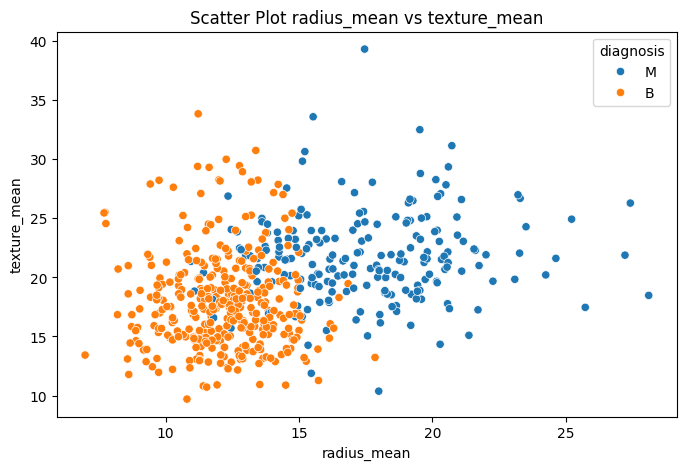

In [3]:
# 202431139_NurAlamFajarAbdullah
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="radius_mean", y="texture_mean", hue="diagnosis")
plt.title("Scatter Plot radius_mean vs texture_mean")
plt.show()

In [4]:
# 202431139_NurAlamFajarAbdullah
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(["diagnosis", "id"], axis=1)
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (455, 30) | Data uji: (114, 30)


In [5]:
# 202431139_NurAlamFajarAbdullah
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

hasil = {}
for nama, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    hasil[nama] = accuracy_score(y_test, y_pred)
    print(f"{nama}: {hasil[nama]*100:.2f}%")

Logistic Regression: 97.37%
KNN (k=5): 94.74%
Decision Tree: 94.74%


Akurasi: 0.9736842105263158
              precision    recall  f1-score   support

           B       0.97      0.99      0.98        71
           M       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



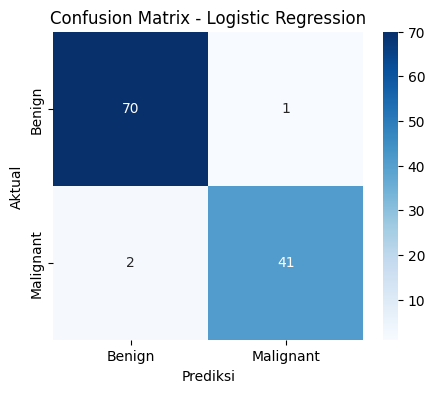

In [6]:
# 202431139_NurAlamFajarAbdullah
from sklearn.metrics import confusion_matrix, classification_report

best = models["Logistic Regression"]
y_pred = best.predict(X_test)

print("Akurasi:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign","Malignant"], yticklabels=["Benign","Malignant"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.show()